# Optimizers Part 1 - Momentum & Nesterov Accelerated Gradient (NAG)

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import warnings 
warnings.filterwarnings('ignore')

In [2]:
A = np.array([1.0, 25.0])

def loss(w):
    return 0.5 * np.sum(A * w**2)

def grad(w):
    return A * w

# 1. Momentum

In [3]:
def classical(w0, lr, beta, steps):
    """v = b*v + g(w);  w = w - lr*v"""
    w, v = w0.copy(), np.zeros_like(w0)
    path = [w.copy()]
    for _ in range(steps):
        v = beta * v + grad(w)
        w = w - lr * v
        path.append(w.copy())
    return np.array(path)

### In Keras Implementation

In [ ]:
from tensorflow.keras.optimizers import SGD

optimizer = SGD(
    learning_rate=0.01, 
    momentum=0.9,
)

# 2. Nesterov Accelerated Gradient (NAG)

In [4]:
def nesterov_lookahead(w0, lr, beta, steps):
    """Original form: gradient at the look-ahead point w - lr*b*v."""
    w, v = w0.copy(), np.zeros_like(w0)
    path = [w.copy()]
    for _ in range(steps):
        g = grad(w - lr * beta * v)       # <- the only change vs classical
        v = beta * v + g
        w = w - lr * v
        path.append(w.copy())
    return np.array(path)

### Keras Implementation

In [ ]:
from tensorflow.keras.optimizers import SGD

optimizer = SGD(
    learning_rate=0.01, 
    momentum=0.9,
    nesterov = True
)

In [5]:
def losses(path):
    return np.array([loss(p) for p in path])


def steps_to(path, tol=1e-3):
    """First step where loss < tol; np.inf if it never gets there / diverges."""
    L = losses(path)
    if not np.all(np.isfinite(L)) or L.max() > 1e12:
        return np.inf
    hit = np.where(L < tol)[0]
    return hit[0] if len(hit) else np.inf


def run_safe(fn, *args):
    with np.errstate(all="ignore"):
        return fn(*args)

In [6]:
w0 = np.array([10.0, 1.0])
lr, beta, steps = 0.05, 0.9, 150

cl = run_safe(classical, w0, lr, beta, steps)
nl = run_safe(nesterov_lookahead, w0, lr, beta, steps)

# 1) steps to reach loss < 1e-3
print(f"\nlr={lr}, beta={beta}, start={tuple(w0)}")
print(f"Classical momentum : {steps_to(cl)} steps to loss < 1e-3")
print(f"Nesterov           : {steps_to(nl)} steps to loss < 1e-3")

# 2) lr sweep: steps-to-converge and divergence point
lrs = np.linspace(0.005, 0.20, 80)
sweep_cl = [steps_to(run_safe(classical, w0, l, beta, 600)) for l in lrs]
sweep_nl = [steps_to(run_safe(nesterov_lookahead, w0, l, beta, 600)) for l in lrs]

def first_diverge(sweep):
    for l, s in zip(lrs, sweep):
        if np.isinf(s):
            return l
    return None

print(f"\nFirst lr (on grid) where classical fails to converge: {first_diverge(sweep_cl)}")
print(f"First lr (on grid) where Nesterov fails to converge:  {first_diverge(sweep_nl)}")


lr=0.05, beta=0.9, start=(np.float64(10.0), np.float64(1.0))
Classical momentum : 78 steps to loss < 1e-3
Nesterov           : 37 steps to loss < 1e-3

First lr (on grid) where classical fails to converge: 0.15310126582278483
First lr (on grid) where Nesterov fails to converge:  0.054367088607594934


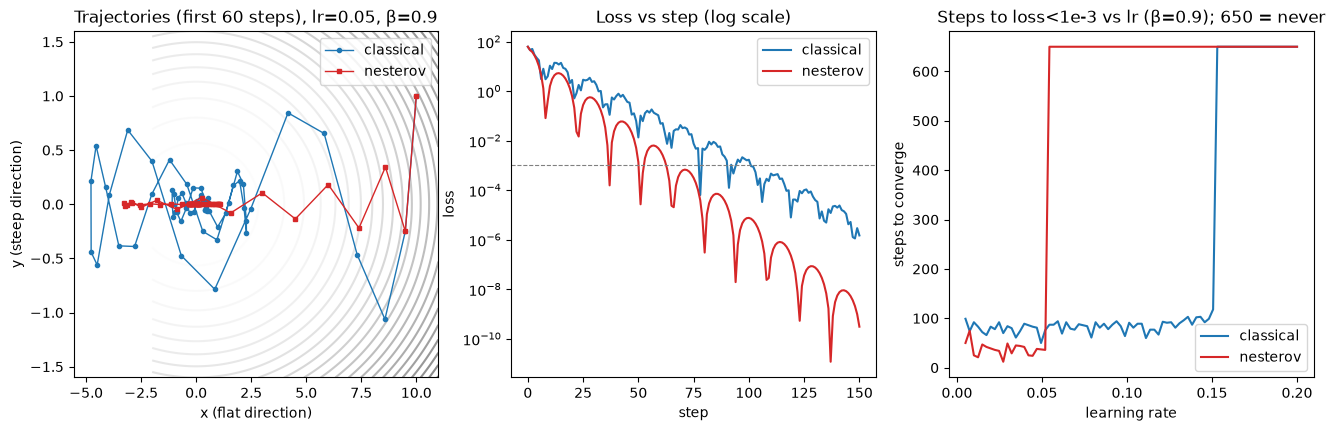

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# contour + trajectories
xs = np.linspace(-2, 11, 300)
ys = np.linspace(-1.6, 1.6, 300)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (A[0] * X**2 + A[1] * Y**2)
ax[0].contour(X, Y, Z, levels=25, cmap="Greys", alpha=0.5)
ax[0].plot(cl[:60, 0], cl[:60, 1], "o-", ms=3, lw=1, label="classical", color="tab:blue")
ax[0].plot(nl[:60, 0], nl[:60, 1], "s-", ms=3, lw=1, label="nesterov", color="tab:red")
ax[0].set_title(f"Trajectories (first 60 steps), lr={lr}, β={beta}")
ax[0].set_xlabel("x (flat direction)")
ax[0].set_ylabel("y (steep direction)")
ax[0].legend()

# loss curves
ax[1].semilogy(losses(cl) + 1e-16, label="classical", color="tab:blue")
ax[1].semilogy(losses(nl) + 1e-16, label="nesterov", color="tab:red")
ax[1].axhline(1e-3, ls="--", color="gray", lw=0.8)
ax[1].set_title("Loss vs step (log scale)")
ax[1].set_xlabel("step")
ax[1].set_ylabel("loss")
ax[1].legend()

# lr sweep
cap = 650
ax[2].plot(lrs, [min(s, cap) for s in sweep_cl], label="classical", color="tab:blue")
ax[2].plot(lrs, [min(s, cap) for s in sweep_nl], label="nesterov", color="tab:red")
ax[2].set_title(f"Steps to loss<1e-3 vs lr (β={beta}); {cap} = never")
ax[2].set_xlabel("learning rate")
ax[2].set_ylabel("steps to converge")
ax[2].legend()

plt.show()